# 08 — Results: Parking occupancy in Los Angeles

## 1. Research question and sample

How is metered parking occupancy associated with the stated price proxy and local demand conditions? I summarize Notebooks 01–07 using **4,016 parking spaces across 45 Census tracts**, with August 2025 time-weighted occupancy as the dependent variable. The primary specification remains the seven-variable Model 3.

Shoup (2006), *Cruising for parking*, connects curb prices, scarce spaces and the incentive to search for parking. Cheap curb parking can encourage cruising when spaces are occupied, so pricing matters for both availability and congestion. This motivates studying occupancy rather than counting transaction records. [Transport Policy, 13(6), 479–486](https://escholarship.org/content/qt55s7079f/qt55s7079f.pdf).

Pierce and Shoup (2013), *Getting the Prices Right: An Evaluation of Pricing Parking by Demand in San Francisco*, studies a program that adjusts parking prices with demand. That setting highlights why a comparison across locations can combine drivers’ response to price with officials’ response to demand. The Los Angeles coefficient below is a conditional association, not the effect of an externally imposed price change. [Journal of the American Planning Association, 79(1), 67–81](https://doi.org/10.1080/01944363.2013.787307).

My starting demand hypothesis is a negative price coefficient, holding demand conditions fixed. I expect density and nearby commercial activity to increase demand; longer time limits may raise occupancy through longer stays, while commuting shares and TOD status have ambiguous signs in this resident-based cross-section. Theory does not pin down a credible numerical magnitude here, so I report percentage-point differences and confidence intervals rather than invent an expected effect size.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset
from statsmodels.stats.stattools import jarque_bera

%matplotlib inline

parking_all = pd.read_csv("../data/processed/parking_cross_section.csv",
                          dtype={"SpaceID": str, "GEOID": str})
parking = parking_all[parking_all["RateType"].isin(["FLAT", "TOD"])].copy()
parking["RateType_TOD"] = (parking["RateType"] == "TOD").astype(int)
predictors = ["price_midpoint", "time_limit_hours", "population_density",
              "nearby_restaurant_retail_count", "drive_alone_share",
              "transit_share", "RateType_TOD"]
variables = ["occupancy_rate", *predictors, "median_income"]
data = parking[variables].dropna().copy()
y = data["occupancy_rate"]
X3 = sm.add_constant(data[predictors])
model3 = sm.OLS(y, X3).fit()
hc1 = sm.OLS(y, X3).fit(cov_type="HC1")
assert len(data) == 4016
assert parking.loc[data.index, "SpaceID"].nunique() == len(data)
print("Original spaces:", len(parking_all))
print("FLAT + TOD:", len(parking), "Common sample:", len(data))
print("Tracts:", parking.loc[data.index, "GEOID"].nunique())

Original spaces: 4139
FLAT + TOD: 4060 Common sample: 4016
Tracts: 45


The original cross-section has **4,139** spaces. Excluding 79 JUMP meters gives **4,060**; the common comparison excludes 44 missing incomes to match Notebook 05, even though income is not a final regressor. Occupancy is occupied valid minutes divided by all valid minutes, using observed state persistence, excluding UNKNOWN-start intervals and gaps over 24 hours, and requiring at least 25 transaction-active days.

Prices and business registrations are October 2026 snapshots. Census predictors use 2020–2024 ACS five-year estimates, 2024 tract boundaries and Gazetteer land area; business counts use a quarter-mile radius. Notebooks 01–03 and the [source catalog](../docs/) document construction and raw paths; none of those data are rebuilt here.

## 2. Descriptive statistics

I report the common estimation sample so the summary matches the regressions. Occupancy and commuting shares are fractions; density is people per square mile, commercial activity is a count of nearby food-service/retail registrations, and TOD is an indicator relative to FLAT.

In [2]:
descriptive = data.describe().T[["count", "mean", "50%", "std", "min", "max"]]
descriptive = descriptive.rename(columns={"50%": "median"})
descriptive["skewness"] = data.skew()
descriptive["excess kurtosis"] = data.kurt()
descriptive.round(4)

,count,mean,median,std,min,max,skewness,excess kurtosis
occupancy_rate,4016.0,0.5376,0.5376,0.1933,0.0038,0.9989,-0.1519,-0.4250
price_midpoint,4016.0,2.0891,1.7500,1.4043,0.5000,8.0000,1.3347,1.8460
time_limit_hours,4016.0,2.4513,2.0000,0.9289,0.2500,4.0000,0.7955,-0.4513
population_density,4016.0,17762.3592,14754.9020,12281.5514,1915.3226,132736.8421,1.4116,7.3598
nearby_restaurant_retail_count,4016.0,229.5194,177.0000,146.4222,21.0000,878.0000,1.1100,1.2198
drive_alone_share,4016.0,0.4197,0.3776,0.1615,0.0889,0.7903,0.5118,-0.5782
transit_share,4016.0,0.0953,0.0708,0.0623,0.0000,0.2711,0.3226,-0.9674
RateType_TOD,4016.0,0.8165,1.0000,0.3871,0.0000,1.0000,-1.6358,0.6762
median_income,4016.0,63083.0583,52412.0000,29658.3726,9375.0000,157115.0000,1.2512,0.9423


## 3. Main EDA findings and remaining checks

Notebook 04 shows histograms, boxplots, scatterplots, a correlation heatmap and IQR flags without deleting flagged observations. Price, income, density and business counts have right tails; population/housing density correlate at about 0.925 and the two business counts at about 0.898. I add the assignment’s continuous-variable density and Q-Q plots below; discrete time limits and TOD remain in the descriptive table rather than being treated as continuous measurements.

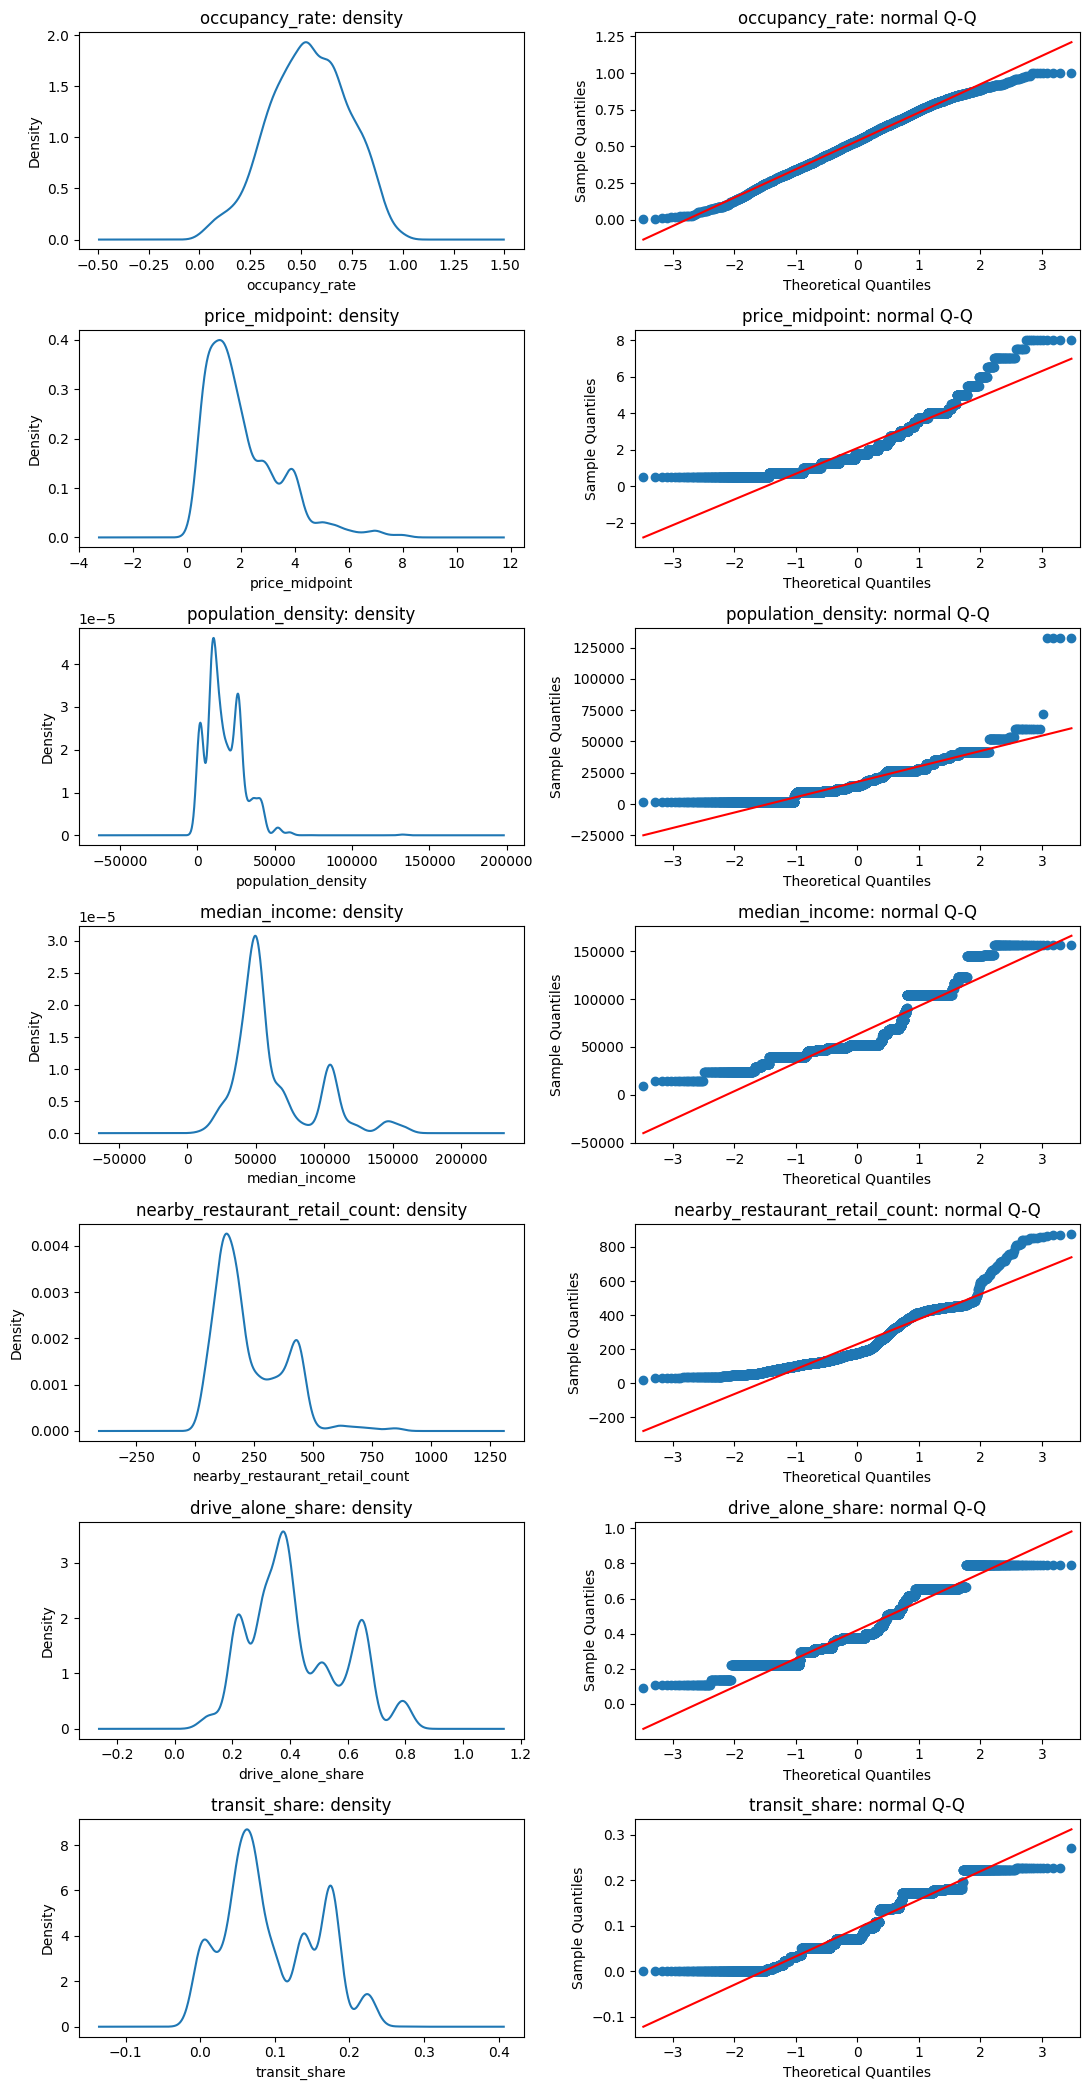

In [3]:
continuous = ["occupancy_rate", "price_midpoint", "population_density",
              "median_income", "nearby_restaurant_retail_count",
              "drive_alone_share", "transit_share"]
fig, axes = plt.subplots(len(continuous), 2, figsize=(11, 3 * len(continuous)))
for i, variable in enumerate(continuous):
    data[variable].plot.density(ax=axes[i, 0])
    axes[i, 0].set_title(variable + ": density")
    axes[i, 0].set_xlabel(variable)
    sm.qqplot(data[variable], line="s", ax=axes[i, 1])
    axes[i, 1].set_title(variable + ": normal Q-Q")
fig.tight_layout()
plt.show()

The density and Q-Q plots show that several predictors depart from a normal distribution, particularly in their upper tails. Predictors do not need to be normally distributed for OLS; these plots motivate checking functional form rather than automatically dropping large values. The log-density sensitivity in Notebook 07 uses the same observations and leaves the original model primary.

I also run the lecture’s Pandas Profiling tool on the FLAT + TOD candidate data before complete-case filtering. The compact summary and alerts below provide evidence about missingness and distributions; they are inspection results, not additional cleaning rules.

In [4]:
import warnings

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=DeprecationWarning,
                            message=r"(?s).*import ydata_profiling.*deprecated.*")
    from ydata_profiling import ProfileReport

profile = ProfileReport(parking[variables].copy(), minimal=True, progress_bar=False)
profile_summary = profile.description_set
print("Profiled observations:", profile_summary.table["n"])
print("Missing cells:", profile_summary.table["n_cells_missing"])
print("Variables with missing values:", profile_summary.table["n_vars_with_missing"])
pd.DataFrame({"Pandas Profiling alert": [str(a) for a in profile_summary.alerts]})

  0%|          | 0/9 [00:00<?, ?it/s]

100%|██████████| 9/9 [00:00<00:00, 2632.22it/s]

Profiled observations: 4060
Missing cells: 44
Variables with missing values: 1


,Pandas Profiling alert
0,[median_income] 44 (1.1%) missing values
1,[occupancy_rate] has unique values
2,[transit_share] has 278 (6.8%) zeros
3,[RateType_TOD] has 737 (18.2%) zeros


In [5]:
missingness = parking[variables].isna().sum().rename("Missing observations")
print(missingness)
missing_income = parking["median_income"].isna()
parking.groupby(missing_income)["occupancy_rate"].agg(["count", "mean", "median"]).rename_axis("Income missing")

occupancy_rate                     0
price_midpoint                     0
time_limit_hours                   0
population_density                 0
nearby_restaurant_retail_count     0
drive_alone_share                  0
transit_share                      0
RateType_TOD                       0
median_income                     44
Name: Missing observations, dtype: int64


,count,mean,median
Income missing,,,
False,4016,0.537639,0.537619
True,44,0.631857,0.687002


Profiling finds **44 missing income values** and no missing values in the seven final predictors or occupancy. Its other alerts identify unique occupancy values and zeros in transit share and TOD status; these do not establish recording errors. The missing-income group has mean occupancy about **0.632**, versus **0.538** for complete incomes, so the exclusion is worth checking rather than assuming it is harmless; Section 9 restores those spaces without imputing income.

## 4. Variable-selection summary

Notebook 05 compares 12 encoded candidates with Boruta, Mallows’ Cp and VIF. Boruta confirms 10 and rejects income and meter type; the lowest Cp is about **9.950** with ten predictors, while the best eight-predictor subset has Cp **11.789** and adjusted R² about **0.294**. The final seven are a simpler economically motivated choice, not the global Cp minimum.

I retain population density and food-service/retail count instead of their strongly correlated alternatives. Each of the seven preferred predictors has VIF below 2, excluding the intercept. I reuse the executed selection results rather than rerun Boruta and all 4,095 subsets here; time limit and transit share are retained for this primary specification even though their final individual tests are insignificant.

In [6]:
pd.DataFrame({
    "Preferred predictor": predictors,
    "Reason": ["Stated price proxy", "Parking time rule", "Residential demand intensity",
               "Nearby commercial activity", "Resident driving pattern", "Resident transit pattern",
               "TOD pricing structure relative to FLAT"]
})

,Preferred predictor,Reason
0,price_midpoint,Stated price proxy
1,time_limit_hours,Parking time rule
2,population_density,Residential demand intensity
3,nearby_restaurant_retail_count,Nearby commercial activity
4,drive_alone_share,Resident driving pattern
5,transit_share,Resident transit pattern
6,RateType_TOD,TOD pricing structure relative to FLAT


## 5. Final regression table

The primary model uses all seven preferred predictors and 4,016 spaces. Because both variance tests reject constant variance, I use **HC1** for the final p-values and 95% intervals, following Lecture 2; conventional OLS standard errors and p-values are shown separately for comparison. HC1 leaves coefficients unchanged and still assumes independent observations.

In [7]:
regression_table = pd.DataFrame({
    "OLS coefficient": model3.params,
    "Conventional SE": model3.bse,
    "HC1 SE": hc1.bse,
    "Conventional p-value": model3.pvalues,
    "HC1 p-value": hc1.pvalues,
    "HC1 95% lower": hc1.conf_int()[0],
    "HC1 95% upper": hc1.conf_int()[1]
})
regression_table.index.name = "Variable"
regression_table.style.format({
    "OLS coefficient": "{:.6g}", "Conventional SE": "{:.6g}", "HC1 SE": "{:.6g}",
    "Conventional p-value": "{:.3e}", "HC1 p-value": "{:.3e}",
    "HC1 95% lower": "{:.6g}", "HC1 95% upper": "{:.6g}"})

,OLS coefficient,Conventional SE,HC1 SE,Conventional p-value,HC1 p-value,HC1 95% lower,HC1 95% upper
Variable,,,,,,,
const,0.456337,0.0157939,0.0171155,6.470e-167,1.291e-156,0.422792,0.489883
price_midpoint,0.0556328,0.00236136,0.00232226,4.731e-115,7.931e-127,0.0510813,0.0601844
time_limit_hours,0.00487929,0.00294796,0.00313717,9.797e-02,1.199e-01,-0.00126946,0.011028
population_density,4.57052e-06,2.21771e-07,2.37074e-07,8.803e-90,8.077e-83,4.10586e-06,5.03518e-06
nearby_restaurant_retail_count,-0.000321282,2.29852e-05,2.4298e-05,2.189e-43,6.502e-40,-0.000368905,-0.000273659
drive_alone_share,-0.198101,0.0208314,0.0211007,3.195e-21,6.095e-21,-0.239458,-0.156744
transit_share,0.0196471,0.0468362,0.0452127,6.749e-01,6.639e-01,-0.0689682,0.108262
RateType_TOD,0.0330042,0.00731608,0.00857071,6.631e-06,1.177e-04,0.0162059,0.0498025


## 6. Economic interpretation

A **$1 higher price proxy is associated with about 5.56 percentage points higher occupancy**, holding the included variables constant; the HC1 95% interval is about **5.11 to 6.02 percentage points**. This is a meaningful difference in monthly occupancy, but it is not a causal effect or a price elasticity: the dependent variable is a fraction in levels and the TOD midpoint is a proxy.

Time limit and transit share remain insignificant at 5% under HC1. The table below rescales every slope and its interval into occupancy percentage points, including those uncertain estimates, so statistical precision is kept separate from economic size.

In [8]:
changes = pd.Series({"price_midpoint": 1, "time_limit_hours": 1,
                     "population_density": 1000, "nearby_restaurant_retail_count": 100,
                     "drive_alone_share": 0.10, "transit_share": 0.10, "RateType_TOD": 1})
economic_effects = pd.DataFrame({
    "Comparison": ["$1 higher proxy", "1 additional hour", "1,000 more people/sq mile",
                   "100 more registrations", "10 pp higher share", "10 pp higher share", "TOD versus FLAT"],
    "Occupancy difference (pp)": hc1.params[predictors] * changes * 100,
    "HC1 95% lower (pp)": hc1.conf_int().loc[predictors, 0] * changes * 100,
    "HC1 95% upper (pp)": hc1.conf_int().loc[predictors, 1] * changes * 100,
    "HC1 p-value": hc1.pvalues[predictors]
})
economic_effects.style.format({"Occupancy difference (pp)": "{:.3f}",
    "HC1 95% lower (pp)": "{:.3f}", "HC1 95% upper (pp)": "{:.3f}", "HC1 p-value": "{:.3e}"})

,Comparison,Occupancy difference (pp),HC1 95% lower (pp),HC1 95% upper (pp),HC1 p-value
price_midpoint,$1 higher proxy,5.563,5.108,6.018,7.931e-127
time_limit_hours,1 additional hour,0.488,-0.127,1.103,1.199e-01
population_density,"1,000 more people/sq mile",0.457,0.411,0.504,8.077e-83
nearby_restaurant_retail_count,100 more registrations,-3.213,-3.689,-2.737,6.502e-40
drive_alone_share,10 pp higher share,-1.981,-2.395,-1.567,6.095e-21
transit_share,10 pp higher share,0.196,-0.690,1.083,6.639e-01
RateType_TOD,TOD versus FLAT,3.300,1.621,4.980,1.177e-04


## 7. Compare fit and prediction

Model 1 uses price alone; Model 2 uses price, population density and nearby food-service/retail count; Model 3 adds time limit, commuting shares and TOD. The corrected middle model has three predictors, as required by the rubric. All comparisons use the same spaces; five-fold errors are verified references from Notebook 06, whose seed-10 splits fit each regression on training rows only.

In [9]:
model1 = sm.OLS(y, sm.add_constant(data[["price_midpoint"]])).fit()
model2 = sm.OLS(y, sm.add_constant(data[["price_midpoint", "population_density",
                                       "nearby_restaurant_retail_count"]])).fit()
models = [model1, model2, model3]
# Verified executed Notebook 06 values; no repeated cross-validation needed here.
cv_rmse = [0.17756368017838295, 0.16820782518065971, 0.16531517414496505]
model_comparison = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"], "Predictors": [1, 3, 7],
    "N": [int(m.nobs) for m in models],
    "Price coefficient": [m.params["price_midpoint"] for m in models],
    "R2": [m.rsquared for m in models], "Adjusted R2": [m.rsquared_adj for m in models],
    "AIC": [m.aic for m in models], "BIC": [m.bic for m in models],
    "Mean five-fold RMSE": cv_rmse
})
model_comparison.round(5)

,Model,Predictors,N,Price coefficient,R2,Adjusted R2,AIC,BIC,Mean five-fold RMSE
0,Model 1,1,4016,0.05451,0.15678,0.15657,-2483.67051,-2471.07443,0.17756
1,Model 2,3,4016,0.05999,0.24350,0.24293,-2915.51726,-2890.32509,0.16821
2,Model 3,7,4016,0.05563,0.27362,0.27235,-3070.71241,-3020.32808,0.16532


Model 3 has the highest adjusted R² (**0.27235**) and lowest AIC (**−3,070.71**), BIC (**−3,020.33**) and mean five-fold RMSE (**0.16532**). It explains about **27.36%** of the within-sample variation; held-out error is about **16.53 occupancy percentage points** in root-mean-square terms. Its improvement over Model 2 is modest, about **0.29 percentage points** of RMSE.

These results compare fixed specifications after selection on the available sample. Random folds may share tracts and nearby spaces between training and test sets, so they are not an independent test of the whole selection process or evidence of performance in a new neighborhood.

## 8. Diagnostic findings

Notebook 07 contains the residual/fitted, scale-location, residual histogram and Q-Q plots. Uneven residual spread and tract bands support caution about variance and functional form; four fitted occupancies exceed one and are left unclipped. I verify the main test values below rather than treat the favorable normality result as approval of all regression assumptions.

In [10]:
bp = het_breuschpagan(model3.resid, X3)
white = het_white(model3.resid, X3)
reset = linear_reset(model3, power=2, test_type="fitted", use_f=True)
jb = jarque_bera(model3.resid)
tests = pd.DataFrame({
    "Test": ["Breusch–Pagan LM (default Koenker)", "White LM", "RESET F", "Jarque–Bera"],
    "Statistic": [bp[0], white[0], float(reset.fvalue), jb[0]],
    "P-value": [bp[1], white[1], float(reset.pvalue), jb[1]]
})
tests.style.format({"Statistic": "{:.3f}", "P-value": "{:.3e}"})

,Test,Statistic,P-value
0,Breusch–Pagan LM (default Koenker),207.230,3.374e-41
1,White LM,394.973,4.755e-63
2,RESET F,122.078,5.605e-28
3,Jarque–Bera,3.836,1.469e-01


Breusch–Pagan (**p ≈ 3.37 × 10⁻⁴¹**) and White (**p ≈ 4.75 × 10⁻⁶³**) reject constant variance, motivating HC1. RESET (**p ≈ 5.60 × 10⁻²⁸**) strongly questions the mean specification; the conventional test should also be read in light of heteroskedasticity. Jarque–Bera (**p ≈ 0.147**) does not reject normality, which does not resolve either concern.

The 4,016 spaces share only **45 tracts**, and several regressors repeat within each tract. Shared neighborhood shocks can correlate their errors, so treating every space as independent may overstate precision. HC1 and the ordinary row bootstrap do not automatically address that dependence; clustered inference was not demonstrated in the available lectures and is not added here.

## 9. Robustness checks

I summarize the existing Cook’s-distance sensitivity and 1,000-draw row bootstrap from Notebook 07 without repeating its bootstrap. I also verify the simple log-density specification, a stricter 28-active-day sample, and the effect of retaining missing-income spaces. None changes the saved outcome, original data or primary specification.

In [11]:
influence = model3.get_influence()
keep = influence.cooks_distance[0] <= 4 / len(data)
cook_model = sm.OLS(y.loc[keep], X3.loc[keep]).fit(cov_type="HC1")

log_data = data.copy()
assert log_data["population_density"].gt(0).all()
log_data["log_population_density"] = np.log(log_data["population_density"])
log_predictors = ["log_population_density" if v == "population_density" else v for v in predictors]
log_X = sm.add_constant(log_data[log_predictors])
log_ols = sm.OLS(y, log_X).fit()
log_model = sm.OLS(y, log_X).fit(cov_type="HC1")
log_reset = linear_reset(log_ols, power=2, test_type="fitted", use_f=True)

days_data = data.loc[parking.loc[data.index, "active_days"].ge(28)]
days_model = sm.OLS(days_data["occupancy_rate"], sm.add_constant(days_data[predictors])).fit(cov_type="HC1")
income_data = parking[["occupancy_rate", *predictors]].dropna()
income_model = sm.OLS(income_data["occupancy_rate"], sm.add_constant(income_data[predictors])).fit(cov_type="HC1")
fits = [hc1, cook_model, log_model, days_model, income_model]
robustness = pd.DataFrame({
    "Check": ["Primary Model 3", "Cook <= 4/n", "Log population density",
              "At least 28 active days", "Retain missing-income spaces"],
    "N": [int(m.nobs) for m in fits],
    "Price coefficient": [m.params["price_midpoint"] for m in fits],
    "HC1 95% lower": [m.conf_int().loc["price_midpoint", 0] for m in fits],
    "HC1 95% upper": [m.conf_int().loc["price_midpoint", 1] for m in fits],
    "Adjusted R2": [m.rsquared_adj for m in fits]
})
print("Log-density RESET p-value:", float(log_reset.pvalue))
print("Log-density AIC:", log_ols.aic, "BIC:", log_ols.bic)
robustness.round(6)

Log-density RESET p-value: 1.4159409411776104e-19
Log-density AIC: -3075.686296466125 BIC: -3025.3019631751527


,Check,N,Price coefficient,HC1 95% lower,HC1 95% upper,Adjusted R2
0,Primary Model 3,4016,0.055633,0.051081,0.060184,0.272354
1,Cook <= 4/n,3767,0.054769,0.051010,0.058528,0.362017
2,Log population density,4016,0.055160,0.050635,0.059686,0.273255
3,At least 28 active days,1609,0.049628,0.041057,0.058199,0.204005
4,Retain missing-income spaces,4060,0.057162,0.052560,0.061763,0.270828


The price estimate stays positive: **0.05477** after the Cook screen, **0.05516** with log density, **0.04963** in the 1,609-space 28-day sample, and **0.05716** when restoring the 44 missing-income spaces. Log density slightly improves adjusted R² to **0.27325**, but RESET still rejects (**p ≈ 1.42 × 10⁻¹⁹**); it does not repair the original model. Fit differences across restricted samples do not prove improvement.

Notebook 07’s **1,000** row-bootstrap draws (seed **90095**) give a price mean of **0.05548**, standard error **0.002374**, and percentile 95% interval **[0.05091, 0.06011]**. All coefficients are summarized there; these are verified references, not a second resampling exercise. The bootstrap assumes independent rows and holds model selection fixed.

Changing the 24-hour interval cutoff to 12/48 hours or expanding eligibility to 20 active days would require rebuilding **3,707,820** raw transactions and checking predictor linkage. That work and a Sunday-reporting comparison remain uncompleted pending approval; the 28-day check alone is not a completed sensor-outcome sensitivity analysis.

## 10. Limitations

The price and business snapshots postdate August 2025 occupancy, and TOD midpoint simplifies varying schedules. High-demand locations may receive higher prices, while omitted employment, destinations and enforcement can affect both; the negative conditional commercial-count estimate also differs from the simple demand expectation. These facts prevent a causal reading of the positive price estimate.

The 24-hour gap cutoff and 25-active-day rule are researcher-selected, and recorded states are assumed to persist until the next transaction. Sensor-equipped spaces and the observed neighborhoods may not represent all Los Angeles parking; registry accounts are not necessarily distinct active storefronts. Shared-tract dependence, remaining RESET rejection and the bounded outcome further limit inference and generalization.

No DFBETAS example or tract-clustered estimator was found in the available lecture notebooks. DFBETAS is explicitly required by the assignment and remains a course-support gap; clustered inference is a limitation, not a separately named rubric requirement.

## 11. Conclusion

Within this sample, higher stated price proxies are associated with higher monthly occupancy after controlling for the included parking and neighborhood variables. The **5.56-percentage-point** estimate is stable in sign across the completed checks, but it does not support the original negative-price hypothesis as a cross-sectional association. It cannot establish that raising prices increases occupancy.

The seven-variable model predicts somewhat better than the simpler alternatives, but the variance, functional-form and dependence concerns prevent calling it fully validated. The results suggest studying demand-responsive pricing with historically aligned data before making policy recommendations. A parking-availability service would also need time-specific outcomes and genuine future/location validation; monthly occupancy is not an instantaneous probability of finding a space.

## 12. Assignment compliance checklist

This follows `project1-1.pdf` and its 130-point rubric. “Complete” means the requested evidence is present, not that a diagnostic passes or the study establishes causality.

| Rubric / requirement | Status and evidence |
|---|---|
| Economic theory (15): question, 2–3 literature paragraphs, at least two academic sources, hypothesis and expected signs/magnitudes | Complete: Section 1; numerical magnitude is not imposed without a theoretical basis |
| Data/EDA (25): cross-section, 500+ rows, five potential predictors; sources, periods and definitions | Complete: 4,016 estimation spaces; Notebooks 01–04 and Sections 1–2 |
| Data/EDA: mean, median, SD, range, skewness, kurtosis | Complete: Section 2 and Notebook 04 |
| Data/EDA: histogram, boxplot, scatter, correlation heatmap; continuous density/Q-Q and nonlinearities | Complete: Notebook 04, Section 3 and functional-form check in Notebook 07 |
| Data/EDA: outliers, missing patterns, treatment/imputation rationale and sensitivity; Profiling findings | Complete: IQR in Notebook 04, residual screens in Notebook 07, Sections 3 and 9; no imputation needed for final regressors |
| Selection (25): Boruta with parameters, Mallows’ Cp, VIF | Complete: Notebook 05; summarized in Section 4 |
| Selection: one-predictor, 2–3-predictor and broader model | Complete: Models 1/2/3 have 1/3/7 predictors; common sample |
| Selection: wording about statistically significant predictors in Model 3 | Needs instructor clarification: original seven retained as instructed, with time limit and transit share insignificant; not a significance-only subset of all candidates |
| Selection: adjusted R², AIC, BIC, CV and final justification | Complete: Notebook 06 and Sections 4 and 7; best of these three, not every possible model |
| Diagnostics (20): residual/fitted, RESET, BP/White, scale-location, histogram, residual Q-Q/JB | Complete: Notebook 07 and Section 8; variance and RESET concerns remain |
| Diagnostics: Cook’s distance, leverage and DFBETAS | Partial: first two complete; DFBETAS required but no worked lecture example found, so still outstanding |
| Diagnostics: 1,000 bootstrap coefficient estimates and comparison with OLS | Complete: Notebook 07 for every coefficient; price summary in Section 9 |
| Diagnostics: five OR ten folds and out-of-sample prediction | Complete: five training-only folds in Notebook 06; post-selection and shared-tract limits disclosed |
| Results (25): all coefficients, SEs, p-values, economic units, CIs, R² and significance versus size | Complete: Sections 5–7; HC1 clearly distinguished from conventional OLS |
| Limitations (10): bias, policy relevance, external validity and extensions | Complete: Sections 8–11; no causal policy claim |
| Code (10): readable programmatic results, reproducible code and fixed seeds | Executed Notebooks 05–08; Boruta seed 10, CV seed 10, bootstrap seed 90095; expensive results referenced with source notebook |
| Additional project sensor checks | 28-day sample completed; interval-cutoff/20-day/Sunday checks remain, requiring a raw-data rebuild rather than a claim of completion |
| Final group PDF/HTML report with member names and Python source | Not yet packaged/submitted; this notebook and Notebooks 01–07 supply the analysis and source |

The methods used follow the available lectures. Cook’s **4/n** screening rule comes from the project instructions; no new advanced method, clustered estimator or DFBETAS implementation is introduced. The saved raw and processed datasets remain unchanged.